# Plasticity plotting

This notebook generates plots to visualize neural plasticity post-patching by comparing outputs of a model finetuned using baseline data for baseline and post-patching data. The inference data is expected to exist under settings.INFERENCE_DIR, organized by model name and fold. The notebook allows you to specify which subjects and conditions to visualize.

In [1]:
import os

import numpy as np
from core import plot_utils
from core import io
from core import settings
import matplotlib.pyplot as plt
from scipy.stats import sem
import mne
from core import plot_data_processing as data_processor

In [2]:
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

model_name = "llrd_norm_5e-3"
subjects = None # set to None to load all subjects
conditions = ["global"]  # set to None to load all conditions
trial_ids = None #[]  # set to None to load all trial ids
bands = None #[] # set to None to visualize all frequency bands


In [3]:
# select appropriate frequency bands based on user input
if bands is None:
    bands = list(settings.FREQ_BANDS.keys())
else:
    loaded = []
    for band in bands:
        for key in settings.FREQ_BANDS.keys():
            if band in key:
                loaded.append(key)
    bands = loaded

### Filter the inference data to only include the specified subjects, conditions, and trial ids

In [4]:

baseline_folds = []
baseline_merged = []
postpatch_folds = []
postpatch_merged = []

for i in range(1, 7):
    b_file_path = settings.INFERENCE_DIR / model_name / str(i) / "baseline_reconstruction.h5"
    p_file_path = settings.INFERENCE_DIR / model_name / str(i) / "postpatch_reconstruction.h5"


    b_fold_trials = io.load_inference_trials(b_file_path)
    baseline_folds.append(b_fold_trials)
    baseline_merged.extend(b_fold_trials)
    p_fold_trials = io.load_inference_trials(p_file_path)
    postpatch_folds.append(p_fold_trials)
    postpatch_merged.extend(p_fold_trials)


print(len(baseline_folds))
print(baseline_folds[0][0].metrics.r2_bandwise)

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

In [5]:
def get_meta_from_key(key, metadata_fields):
    parts = key.split("/")
    metadata = {}
    for field in metadata_fields:
        if field == "subject":
            for part in parts:
                if part.startswith("STMD"):
                    metadata[field] = part
                    break
        elif field == "idx":
            for part in parts:
                if part.isdigit():
                    metadata[field] = part
    return metadata


def extract_data(all_folds, searched, return_metadata = None, return_keys = False):
    matched = []
    metadata = []
    if return_keys:
        matched = {}
    for fold_data in all_folds:
        for key, data in fold_data.items():
            parts = key.split("/")
            if searched in parts:
                if return_keys:
                    matched[key] = data
                else:
                    matched.append(data)
                if not return_metadata:
                    continue
                metadata.append(get_meta_from_key(key, return_metadata))
    return matched, metadata


def extract_normalized_data(all_folds, normalize_by, searched, bands = None):

    normalized = {band: [] for band in bands} if bands else []
    for fold_data in all_folds:
        for key, data in fold_data.items():
            parts = key.split("/")
            if normalize_by in parts:
                std_axis = data.ndim - 1
                std = np.mean(np.std(data, axis = std_axis, ddof = 1))
                if std == 0:
                    print("Standard deviation is zero for key:", key)
                    continue
                path_parts = [p for p in parts if p != normalize_by]
                matched_key = "/".join(path_parts)

                target_keys = [k for k in fold_data.keys() if f"{matched_key}/" in k and searched in k.split("/")]

                if len(target_keys) == 0:
                    print("Target key not found for key:", key)
                    continue
                if not bands and len(target_keys) > 1:
                    print("WARNING: Multiple target keys found for key:", key, target_keys)
                    continue
                for target_key in target_keys:
                    target_data = fold_data[target_key]
                    if bands:
                        normalized[target_key.split("/")[-1]].append(target_data / std)
                    else:
                        normalized.append(target_data / std)
    return normalized


def avg_over_folds(all_folds, metric):
    matched = []
    for fold_data in all_folds:
        for key, data in fold_data.items():
            parts = key.split("/")
            if metric in parts:
                matched.append(data)
    return np.mean(matched)

def calc_nmae(target, output, channel, sample, bands, freqs): # TODO
    std_axis = target.ndim - 1
    std = np.mean(np.std(target, axis = std_axis, ddof = 1))
    if std == 0:
        print("Standard deviation is zero for channel:", channel, "in sample:", sample)
        metrics = None

    bandwise = {}
    for band_name, band in bands.items():
        low, high = band
        band_indices = np.where((freqs >= low) & (freqs <= high))[0]
        target_band = target[band_indices]
        output_band = output[band_indices]
        band_mae = np.mean(np.abs(target_band - output_band))

        band_std = np.mean(np.std(target_band, axis=std_axis, ddof=1))

        if band_std == 0:
            print("Standard deviation is zero for band:", band_name, "in channel:", channel, "in sample:", sample)
            band_nmae = None
        else:
            band_nmae = band_mae / band_std
        bandwise[band_name] = band_nmae

    metrics = {
        "nmae": np.mean(np.abs(target - output)) / std,
        "bandwise_nmae": bandwise,
    }
    return metrics

def get_channel_maes(channelwise_dataset, n_chans, bands): # TODO
    results = {f"ch_{i}": [] for i in range(n_chans)}

    # Temporary storage to group metrics by trial (subject/condition/idx)
    # structure: grouping[channel][trial_prefix] = {mae, mae_bandwise}
    grouping = {f"ch_{i}": {} for i in range(n_chans)}

    for fold_data in channelwise_dataset:
        for key, value in fold_data.items():
            parts = key.split("/")
            # Expected path: subject/condition/idx/ch_N/metric_name/...
            if len(parts) < 7:
                continue

            trial_prefix = "/".join(parts[1:4]) # e.g., 'STMD_01/global/0'
            channel = parts[5]
            metric_name = parts[6]

            if channel not in grouping:
                continue

            if trial_prefix not in grouping[channel]:
                grouping[channel][trial_prefix] = {
                    band: None for band in bands
                }

            if metric_name == "mae":
                grouping[channel][trial_prefix]["mae"] = value
            elif metric_name == "mae_bandwise" and len(parts) > 7:
                band_name = parts[7]
                if band_name in grouping[channel][trial_prefix]:
                    grouping[channel][trial_prefix][band_name] = value



    # Convert the grouped dictionary into the final list-based structure
    for chan in grouping:
        for trial_prefix, metric_dict in grouping[chan].items():
            target = None
            for fold_data in channelwise_dataset:
                target_key = f"/{trial_prefix}/target"
                if target_key in fold_data:
                    target = fold_data[target_key]
                    break
            if target is None:
                print(f"Target data not found for trial: {trial_prefix}, channel: {chan}")
                continue
            target_std = np.mean(np.std(target[int(chan[3:])], axis=1, ddof=1)) # extract channel index from 'ch_N' format

            freq_window = settings.SPECTRAL_DECODER_PARAMS["freq_window"]
            n_freqs = settings.SPECTRAL_DECODER_PARAMS["n_freqs"]
            freqs = np.geomspace(freq_window[0], freq_window[1], n_freqs)
            bandwise_target_std = {}
            for band_name, band in settings.FREQ_BANDS.items():
                low, high = band
                band_indices = np.where((freqs >= low) & (freqs <= high))[0]
                target_band = target[int(chan[3:]), band_indices]
                bandwise_target_std[band_name] = np.mean(np.std(target_band, axis=1, ddof=1))


            grouping[chan][trial_prefix]["nmae"] = metric_dict["mae"] / (target_std+settings.EPS) if target_std != 0 else 0.0
            for band in settings.FREQ_BANDS.keys():
                band_mae = metric_dict[band]
                band_std = bandwise_target_std[band]
                grouping[chan][trial_prefix][f"nmae_{band}"] = band_mae / (band_std+settings.EPS) if band_std != 0 else 0.0

        results[chan] = list(grouping[chan].values())

    # Example access:

    return results

# Plotting the difference between baseline and post-patching performance

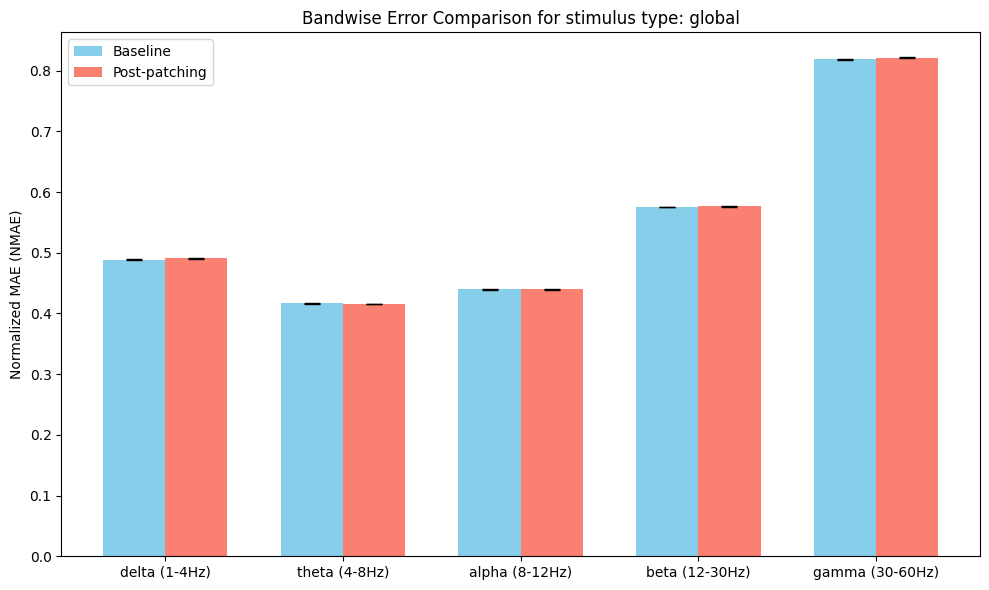

In [6]:


baseline_means, baseline_sems = data_processor.get_global_bandwise_metric_mean(baseline_merged, metric_name="nmae_bandwise", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_global_bandwise_metric_mean(postpatch_merged, metric_name="nmae_bandwise", bands=settings.FREQ_BANDS)

#print(baseline_sems)
# plot bar chart comparing baseline and post-patching nmae for each frequency band with error bars
fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(settings.FREQ_BANDS))
title = f'Bandwise Error Comparison for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, baseline_means.values(), width=width, yerr=baseline_sems.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, postpatch_means.values(), width=width, yerr=postpatch_sems.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.set_xticklabels(baseline_means.keys())

# Formatting
ax.set_ylabel('Normalized MAE (NMAE)')
ax.set_title(f'Bandwise Error Comparison for stimulus type: {", ".join(conditions)}')
ax.legend()
plot_utils.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_e_comparison", default_name=f"{model_name}_{'_'.join(conditions)}_error")
plt.tight_layout()
plt.show()

In [7]:
baseline_merged

[Trial(trial_data=<HDF5 group "/STMD14/center_2/1" (4 members)>, subject='STMD14', condition='center_2', idx='1'),
 Trial(trial_data=<HDF5 group "/STMD14/center_2/10" (4 members)>, subject='STMD14', condition='center_2', idx='10'),
 Trial(trial_data=<HDF5 group "/STMD14/center_2/11" (4 members)>, subject='STMD14', condition='center_2', idx='11'),
 Trial(trial_data=<HDF5 group "/STMD14/center_2/12" (4 members)>, subject='STMD14', condition='center_2', idx='12'),
 Trial(trial_data=<HDF5 group "/STMD14/center_2/13" (4 members)>, subject='STMD14', condition='center_2', idx='13'),
 Trial(trial_data=<HDF5 group "/STMD14/center_2/14" (4 members)>, subject='STMD14', condition='center_2', idx='14'),
 Trial(trial_data=<HDF5 group "/STMD14/center_2/15" (4 members)>, subject='STMD14', condition='center_2', idx='15'),
 Trial(trial_data=<HDF5 group "/STMD14/center_2/16" (4 members)>, subject='STMD14', condition='center_2', idx='16'),
 Trial(trial_data=<HDF5 group "/STMD14/center_2/17" (4 members)>, 

## Single channel comparison viewer

In [ ]:
input_metrics = []

input_metrics.append(data_processor.get_channel_viewer_metrics(baseline_merged, ["nmae", "nmae_bandwise"], ))
input_metrics.append(data_processor.get_channel_viewer_metrics(postpatch_merged, ["nmae", "nmae_bandwise"], ))

In [8]:

input_data = [baseline_merged, postpatch_merged]
styling_params = {
        "param_text": "",
        #"suptitle": f"Single channel reconstruction comparison for stimulus type: {', '.join(conditions)}",
        "suptitle": f"Single channel reconstruction comparison for stimulus type: ",
        "apply_log": False,
        "target_mode": "wavelet",
}
save_dir = settings.PLOT_INFERENCE/"single_channel_comparison"/f"{'_'.join(conditions)}"
plot_utils.single_channel_viewer(input_data, input_metrics, n_chans=settings.N_CHANNELS, styling_params=styling_params, save_dir=save_dir, bands=settings.FREQ_BANDS.keys())

KeyboardInterrupt: 

## Topomaps of global and bandwise error for given condition

In [ ]:
baseline_chs = get_channel_maes(all_baseline_channelwise, n_chans, settings.FREQ_BANDS.keys())
postpatch_chs = get_channel_maes(all_postpatch_channelwise, n_chans, settings.FREQ_BANDS.keys())

print("Baseline channelwise MAEs for ch_0:", baseline_chs["ch_0"][0])
print("Post-patching channelwise MAEs for ch_0:", postpatch_chs["ch_0"][0])

# Extract all available metric keys (e.g., 'mae' and individual frequency bands)
metric_keys = list(key for key in baseline_chs["ch_0"][0].keys() if key.startswith("nmae")) # focus on nmae metrics for topomap visualization

baseline_final = {}
postpatch_final = {}

for key in metric_keys:
    b_means, b_stds = [], []
    p_means, p_stds = [], []

    # Iterate through channels in order (ch_0, ch_1, ...)
    for i in range(n_chans):
        chan_id = f"ch_{i}"

        # Collect values across all trials for this specific channel and metric
        b_vals = [trial[key] for trial in baseline_chs[chan_id] if trial[key] is not None]
        p_vals = [trial[key] for trial in postpatch_chs[chan_id] if trial[key] is not None]


        # Calculate statistics
        b_means.append(np.mean(b_vals))
        b_stds.append(np.std(b_vals, ddof=1))
        p_means.append(np.mean(p_vals))
        p_stds.append(np.std(p_vals, ddof=1))

    # Store results as numpy arrays (length n_chans) for topomap plotting
    baseline_final[key] = {"mean": np.array(b_means), "std": np.array(b_stds)}
    postpatch_final[key] = {"mean": np.array(p_means), "std": np.array(p_stds)}


# Example usage for plotting:
# plot_topomap(baseline_final["mae"]["mean"], ...)
# print(f"Calculated statistics for metrics: {baseline_final['gamma (30-60Hz)']['mean']}")
# print(f"Mean baseline MAE for ch_0: {baseline_final['mae']['mean'][0]:.4f}")

metric_channel_glass = {}

for key in metric_keys:
    if not "nmae" in key:
            continue
    ch_glass = []
    for i in range(n_chans):

        b_mae_mean = baseline_final[key]['mean'][i]
        b_mae_std = baseline_final[key]['std'][i]
        p_mae_mean = postpatch_final[key]['mean'][i]

        if b_mae_std == 0:
            print(f"Standard deviation is zero for channel {i}, skipping Glass calculation.")
            ch_glass.append(0)
            continue
        glass = (p_mae_mean - b_mae_mean) / b_mae_std
        ch_glass.append(glass)
    metric_channel_glass[key] = ch_glass
ch_names = [settings.CHORDER_STANDARD[i] for i in range(n_chans)]

for i, name in enumerate(ch_names):
    mod_name = name.split(' ')[-1].split('-')[0]
    if mod_name == "T1":
        ch_names[i] = "FT9"
        continue
    if mod_name == "T2":
        ch_names[i] = "FT10"
        continue
    if mod_name[1].isdigit():
        ch_names[i] = mod_name
        continue
    mod_name = mod_name[0] + mod_name[1].lower() + mod_name[2:]
    ch_names[i] = mod_name

info = mne.create_info(ch_names=ch_names, sfreq=settings.RSFREQ, ch_types='eeg') # sfreq is required but not relevant for static topomap
montage = mne.channels.make_standard_montage('standard_1005')
info.set_montage(montage)

# create 1x5 subplot for global MAE and each frequency band's MAE with topomap of Glass's delta values
fig, axes = plt.subplots(1, len(metric_keys), figsize=(24, 4))

for idx, key in enumerate(metric_keys):
    if "nmae" not in key:
        continue
    max_val = max(np.abs(metric_channel_glass[key]))
    vlim = (-max_val, max_val)
    glass_values = metric_channel_glass[key]
    im, _ = mne.viz.plot_topomap(glass_values, info, axes=axes[idx], show=False, vlim=vlim, cmap="RdBu_r")
    if key == "nmae":
        axes[idx].set_title(f"Global Glass's Δ")
    else:
        axes[idx].set_title(f"Glass's Δ for {key.replace('nmae_', '')}")
    fig.colorbar(im, ax=axes[idx])
plt.suptitle(f"Topomaps of Glass's Δ for stimulus type: {', '.join(conditions)}", y=1.02)
plot_utils.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_topomaps", default_name=f"{model_name}_{'_'.join(conditions)}_topomaps")

plt.tight_layout()
plt.show()


## plotting bandwise power changes pre- and post-patching

In [ ]:
pre_means = [np.mean(bandwise_powers_pre[band]) for band in bandwise_powers_pre.keys()]
pre_sems = [sem(bandwise_powers_pre[band]) for band in bandwise_powers_pre.keys()]
post_means = [np.mean(bandwise_powers_post[band]) for band in bandwise_powers_post.keys()]
post_sems = [sem(bandwise_powers_post[band]) for band in bandwise_powers_post.keys()]
x_text = list(bandwise_powers_pre.keys())

fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(x_text))
title = f'Bandwise Power Comparison for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, pre_means, width=width, yerr=pre_sems, label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, post_means, width=width, yerr=post_sems, label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.set_xticklabels(x_text)

# Formatting
ax.set_ylabel('Mean Z-scored Band Power')
ax.set_title(title)
ax.legend()

plt.tight_layout()
plt.show()